# TEMA 3: FILTRADO ESPACIAL

In [1]:
import cv2 as cv 
import matplotlib.pyplot as plt  
import numpy as np

## Ruido sal y pimienta:

Definimos una función para introducir en una imagen ruido sal y pimienta, lo cual consiste en asignar, de manera aleatoria, valores 0 (pimienta) y 255 (sal) a un número determinado de pixeles

In [2]:
import random

def ruido(image, a, b):
    aleat = np.random.randint(1,101, size = (image.shape[0], image.shape[1]))
    image2 = np.where(aleat <=100*a, 0, image) # ruido pimienta
    out = np.where(aleat > 100-100*b, 255, image2) # ruido sal

    return out

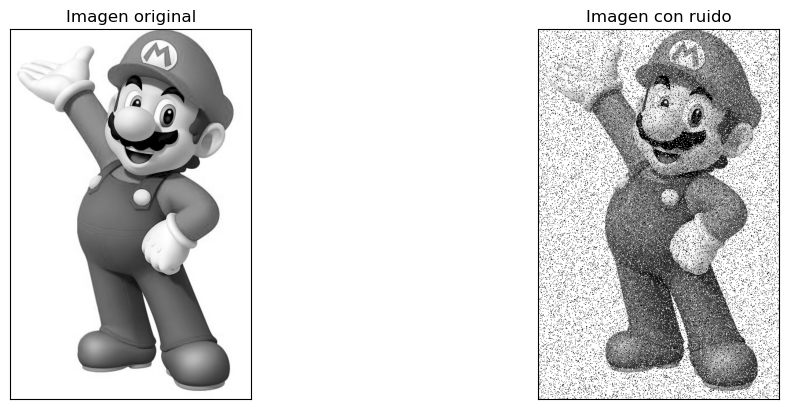

In [6]:
img = cv.imread('mario.png',0)
img_ruido = ruido(img, 0.1, 0.1) # Juega con los valores de a y b para ver qué hacen estos parámetros

plt.subplots_adjust(left = None, bottom = None, right = 1.5, top = None, wspace = 0.5, hspace = 0.5) 

plt.subplot(1,2,1)
plt.title('Imagen original')
plt.xticks([]), plt.yticks([])
plt.imshow(img, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,2,2)
plt.title('Imagen con ruido')
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido, cmap = 'gray', vmin = 0, vmax = 255)

## Ruido gaussiano:

El ruido gaussiano (o ruido normal) sigue una distribución normal y es común en el procesamiento de imágenes. Podemos añadirlo a una imagen usando NumPy para generar números aleatorios con distribución normal.

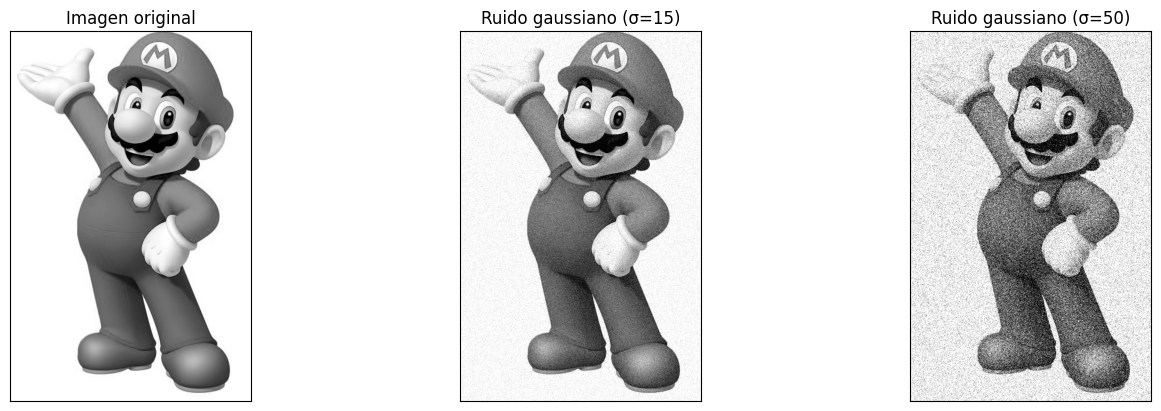

In [169]:
def ruido_gaussiano(image, mean=0, sigma=25):
    # Generamos una matriz de ruido del mismo tamaño que la imagen
    # con distribución normal (gaussiana)
    ruido = np.random.normal(mean, sigma, image.shape)
    
    # Añadimos el ruido a la imagen
    img_ruido = image + ruido
    
    # Aseguramos que los valores estén en el rango [0,255]
    img_ruido = np.clip(img_ruido, 0, 255)
    
    # Convertimos a uint8 para mantener el formato de imagen
    return np.uint8(img_ruido)

# Aplicamos diferentes niveles de ruido gaussiano
img_ruido_gauss1 = ruido_gaussiano(img, mean=0, sigma=15)  # Ruido suave
img_ruido_gauss2 = ruido_gaussiano(img, mean=0, sigma=50)  # Ruido más fuerte

# Mostramos los resultados
plt.subplots_adjust(left=None, bottom=None, right=2, top=None, wspace=0.5, hspace=0.5)

plt.subplot(1,3,1)
plt.title('Imagen original')
plt.xticks([]), plt.yticks([])
plt.imshow(img, cmap='gray', vmin=0, vmax=255)

plt.subplot(1,3,2)
plt.title('Ruido gaussiano (σ=15)')
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido_gauss1, cmap='gray', vmin=0, vmax=255)

plt.subplot(1,3,3)
plt.title('Ruido gaussiano (σ=50)')
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido_gauss2, cmap='gray', vmin=0, vmax=255)

También podemos usar la función 
    cv.randn(matriz,media,desviacionestandar)
Llena la matriz con valores aleatorios que siguen una distribución normal (gaussiana)

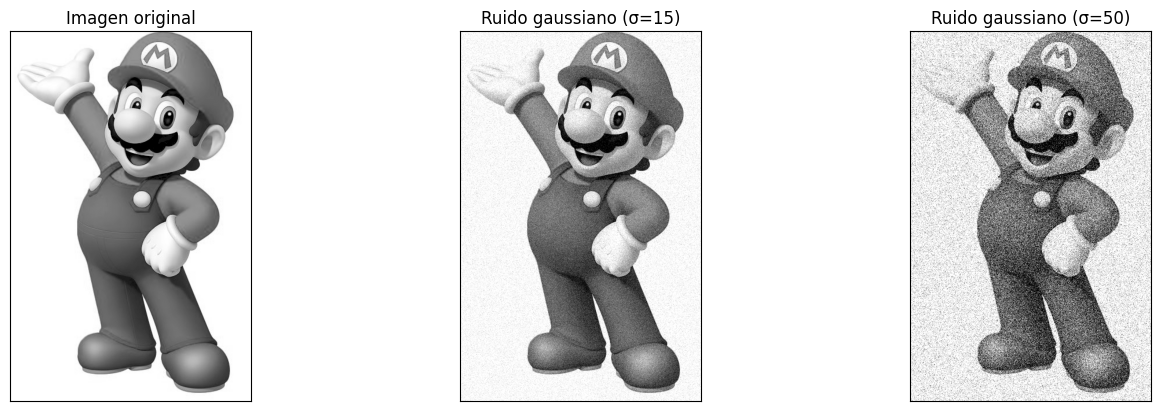

In [170]:
def ruido_gaussiano_2(image, mean=0, sigma=25):
    # Generamos una matriz de ruido del mismo tamaño que la imagen
    # con distribución normal (gaussiana)
    ruido = np.zeros(image.shape, dtype=np.uint8)
    cv.randn(ruido,128,20)
    ruido=(ruido*0.5)

    # Añadimos el ruido a la imagen
    img_ruido = image + ruido
    
    # Aseguramos que los valores estén en el rango [0,255]
    img_ruido = np.clip(img_ruido, 0, 255)
    
    # Convertimos a uint8 para mantener el formato de imagen
    return np.uint8(img_ruido)

# Aplicamos diferentes niveles de ruido gaussiano
img_ruido_gauss1 = ruido_gaussiano(img, mean=0, sigma=15)  # Ruido suave
img_ruido_gauss2 = ruido_gaussiano(img, mean=0, sigma=50)  # Ruido más fuerte

# Mostramos los resultados
plt.subplots_adjust(left=None, bottom=None, right=2, top=None, wspace=0.5, hspace=0.5)

plt.subplot(1,3,1)
plt.title('Imagen original')
plt.xticks([]), plt.yticks([])
plt.imshow(img, cmap='gray', vmin=0, vmax=255)

plt.subplot(1,3,2)
plt.title('Ruido gaussiano (σ=15)')
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido_gauss1, cmap='gray', vmin=0, vmax=255)

plt.subplot(1,3,3)
plt.title('Ruido gaussiano (σ=50)')
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido_gauss2, cmap='gray', vmin=0, vmax=255)


## Filtrado general:

Dada una imagen **I** y una máscara **mask** definida manualmente como una matriz de números, podemos filtrar dicha imagen usando la siguiente función:

    cv.filter2D(I, -1, mask)
    
donde el parámetro -1 indica que la función utilizará el mismo tipo de datos que la imagen de entrada (8 bits, 32 bits, float...).

In [65]:
img = cv.imread('mario.png',0)
mask = np.array([[-1,-1,-1],[1,4,1],[-0.1,-1,-0.1]])
img_filter = cv.filter2D(img, -1, mask)

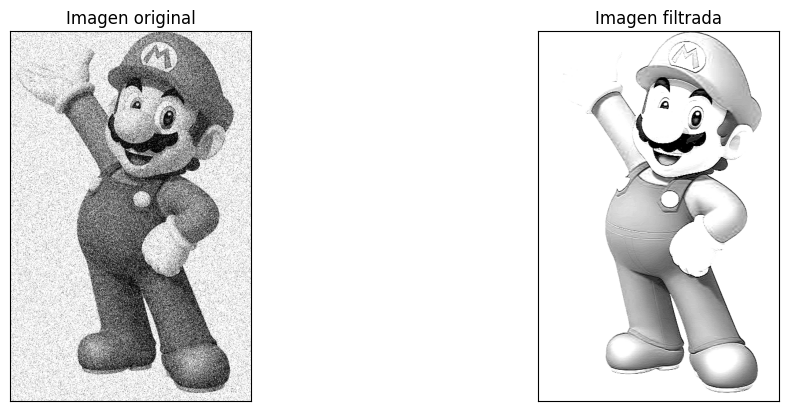

In [66]:
plt.subplots_adjust(left = None, bottom = None, right = 1.5, top = None, wspace = 0.5, hspace = 0.5) 

plt.subplot(1,2,1)
plt.title('Imagen original')
plt.xticks([]), plt.yticks([]) 
plt.imshow(img_ruido_gauss2, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,2,2)
plt.title('Imagen filtrada')
plt.xticks([]), plt.yticks([])
plt.imshow(img_filter, cmap = 'gray', vmin = 0, vmax = 255)

La función `filter2D` permite especificar cómo manejar los bordes de la imagen usando el parámetro `borderType`. Los tipos más comunes son:

- `cv.BORDER_DEFAULT` o `cv.BORDER_REFLECT_101`: refleja los píxeles del borde (es el valor por defecto)
- `cv.BORDER_CONSTANT`: rellena con un valor constante (negro por defecto)
- `cv.BORDER_REPLICATE`: repite el último píxel
- `cv.BORDER_REFLECT`: refleja los píxeles del borde incluyendo el propio borde
- `cv.BORDER_TRANSPARENT`: mantiene los píxeles del borde sin cambios

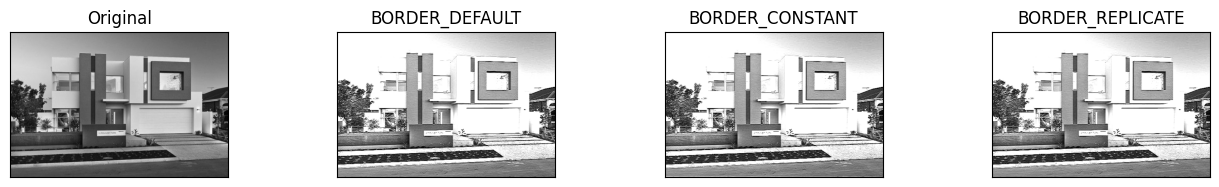

In [68]:
img = cv.imread('casa.jpg',0)
mask = np.array([[-1,-1,-1],[1,4,1],[-0.1,-1,-0.1]])

# Aplicamos el mismo filtro con diferentes tipos de borde
img_default = cv.filter2D(img, -1, mask, borderType=cv.BORDER_DEFAULT)
img_constant = cv.filter2D(img, -1, mask, borderType=cv.BORDER_CONSTANT)
img_replicate = cv.filter2D(img, -1, mask, borderType=cv.BORDER_REPLICATE)

# Mostramos los resultados
plt.subplots_adjust(left=None, bottom=None, right=2, top=None, wspace=0.5, hspace=0.5)

plt.subplot(1,4,1)
plt.title('Original')
plt.xticks([]), plt.yticks([])
plt.imshow(img, cmap='gray', vmin=0, vmax=255)

plt.subplot(1,4,2)
plt.title('BORDER_DEFAULT')
plt.xticks([]), plt.yticks([])
plt.imshow(img_default, cmap='gray', vmin=0, vmax=255)

plt.subplot(1,4,3)
plt.title('BORDER_CONSTANT')
plt.xticks([]), plt.yticks([])
plt.imshow(img_constant, cmap='gray', vmin=0, vmax=255)

plt.subplot(1,4,4)
plt.title('BORDER_REPLICATE')
plt.xticks([]), plt.yticks([])
plt.imshow(img_replicate, cmap='gray', vmin=0, vmax=255)

# Veamos los filtros que tiene implementados la librería opencv:

# FILTROS DE SUAVIZADO:

## Filtro de la media:

El filtro de la media consiste en modificar el valor del nivel de gris de un pixel (x,y), f(x,y), por la media de los niveles de grises de los pixeles en un entorno del pixel procesado.

La función de opencv para aplicar este filtro es:

    cv2.blur(image, ksize)
    
donde ksize = (ancho, alto) determina el tamaño de la máscara, siendo valores impares y positivos.

El filtro de la media (o filtro promedio) reemplaza el valor de cada píxel por el promedio de todos los píxeles que están a su alrededor dentro de una mascara de tamaño determinado.

Los valores de la mascara ienen que ser impares ($3 \times 3$, $5 \times 5$, $15 \times 15$, etc.) para que el kernel tenga un píxel central exacto sobre el cual aplicar el valor promedio calculado. 

Cuanto más grande sea la máscara, más borrosa/desenfocada se verá la imagen. Sirve principalmente para eliminar grano o ruido continuo, aunque a costa de perder nitidez en los bordes y detalles finos

In [9]:
img = cv.imread('mario.png',0)
img_media15 = cv.blur(img,(15,15))
img_media25 = cv.blur(img,(25,25))

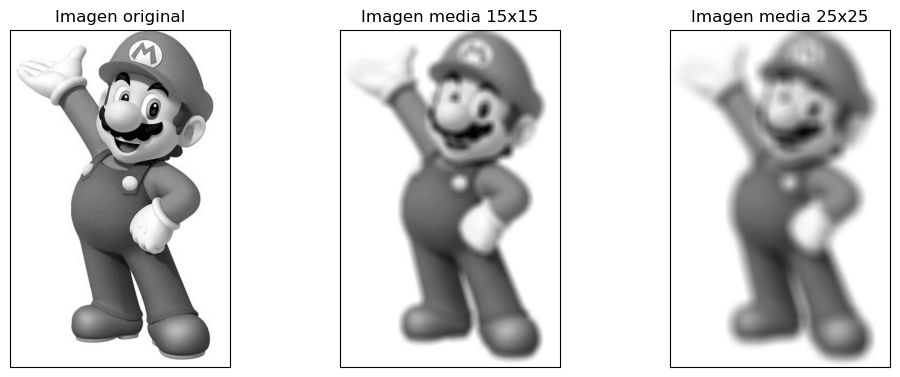

In [10]:
plt.subplots_adjust(left = None, bottom = None, right = 1.5, top = None, wspace = 0.5, hspace = 0.5) 

plt.subplot(1,3,1)
plt.title('Imagen original')
plt.xticks([]), plt.yticks([])
plt.imshow(img, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,2)
plt.title('Imagen media 15x15')
plt.xticks([]), plt.yticks([])
plt.imshow(img_media15, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,3)
plt.title('Imagen media 25x25')
plt.xticks([]), plt.yticks([])
plt.imshow(img_media25, cmap = 'gray', vmin = 0, vmax = 255)

### Filtro Box (BoxFilter):

OpenCV también proporciona `cv.boxFilter()`, que es similar al filtro de la media pero con la opción de normalización:

    cv.boxFilter(src, ddepth, ksize, normalize=True)

- `src`: imagen de entrada
- `ddepth`: profundidad de la imagen de salida (-1 para usar la misma que la entrada)
- `ksize`: tamaño del kernel (ancho, alto)
- `normalize`: si es True (por defecto), divide por el área del kernel; si es False, no normaliza

Cuando `normalize=True`, es equivalente a `cv.blur()`.

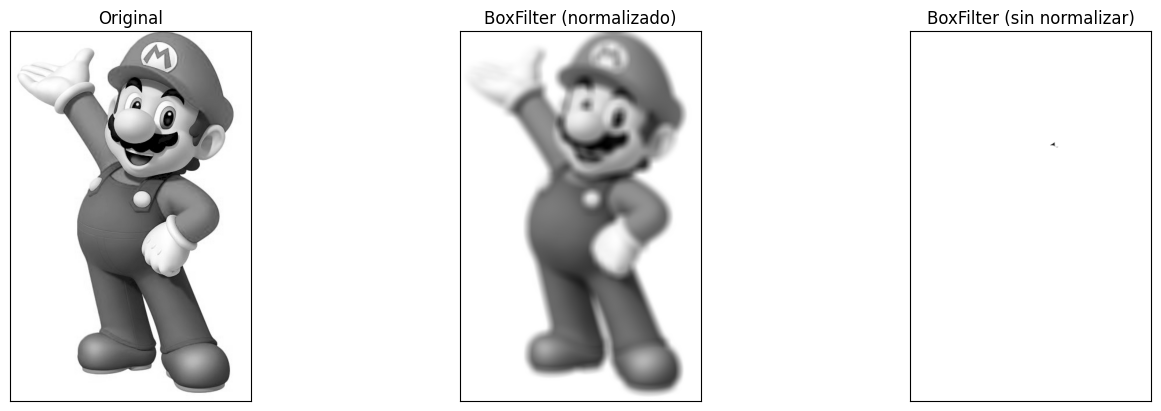

In [81]:
# Aplicamos BoxFilter con y sin normalización
box_norm = cv.boxFilter(img, -1, (15,15), normalize=True)   # Equivalente a cv.blur()
box_no_norm = cv.boxFilter(img, -1, (15,15), normalize=False)  # Sin normalización

# Mostramos los resultados
plt.subplots_adjust(left=None, bottom=None, right=2, top=None, wspace=0.5, hspace=0.5)

plt.subplot(1,3,1)
plt.title('Original')
plt.xticks([]), plt.yticks([])
plt.imshow(img, cmap='gray', vmin=0, vmax=255)

plt.subplot(1,3,2)
plt.title('BoxFilter (normalizado)')
plt.xticks([]), plt.yticks([])
plt.imshow(box_norm, cmap='gray', vmin=0, vmax=255)

plt.subplot(1,3,3)
plt.title('BoxFilter (sin normalizar)')
plt.xticks([]), plt.yticks([])
plt.imshow(box_no_norm, cmap='gray', vmin=0, vmax=255)

Probamos ahora con la imagen a color directamente:

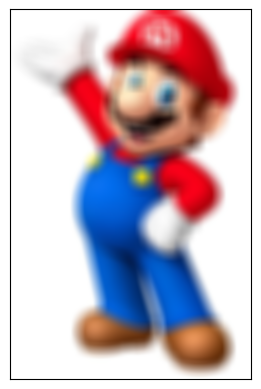

In [82]:
img_color = cv.imread('mario.png')
img_media_color = cv.blur(img_color,(25,25))

plt.xticks([]), plt.yticks([])
plt.imshow(cv.cvtColor(img_media_color, cv.COLOR_BGR2RGB))

### Filtro gaussiano:

Filtra la imagen usando máscaras que implementan la función gaussiana, la cuál depende de un parámetro sigma (desvación típica). La función de opencv que realiza el filtro gaussiano es:

    - cv.GaussianBlur(image, ksize, sigma)
    
donde ksize = (ancho, alto) determina el tamaño de la máscara y sigma controla la extensión o el alcance del suavizado. Un valor más alto de sigma resultará en un suavizado más amplio, es decir, una difuminación más fuerte, que afectará a un área más grande alrededor de cada píxel en la imagen. Por otro lado, un valor más bajo de sigma dará como resultado un suavizado más suave, que afectará a un área más pequeña alrededor de cada píxel y conservará más detalles finos.

Si damos al parámero sigma el valor 0, eso significa que el valor de la desviacón típica sigma se calculará a partir del tamaño de máscara.  

El filtro gaussiano es otro método de suavizado, pero a diferencia del filtro de media donde todos los píxeles vecinos pesan lo mismo, este da más peso a los píxeles cercanos al centro y menos peso a los más lejanos siguiendo una curva gaussiana (campana de Gauss).

In [178]:
img_gaussian15 = cv.GaussianBlur(img_ruido_gauss1, (11, 11), 0)
img_gaussian25 = cv.GaussianBlur(img_ruido_gauss1, (25, 25), 0)

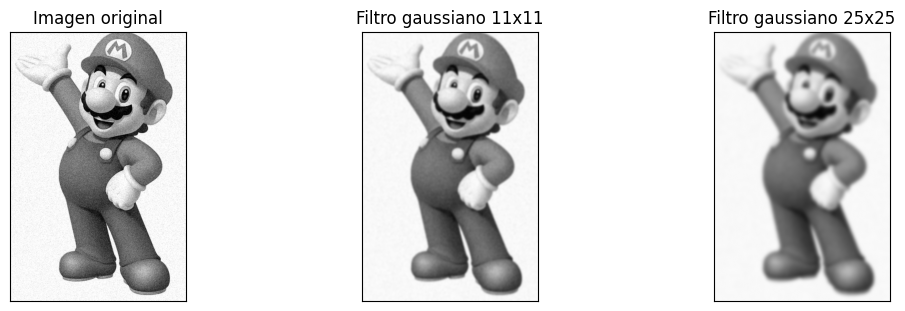

In [180]:
plt.subplots_adjust(left = None, bottom = None, right = 1.5, top = None, wspace = 1, hspace = 1) #ajustes del subplot

plt.subplot(1,3,1)
plt.title('Imagen original')
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido_gauss1, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,2)
plt.title('Filtro gaussiano 11x11')
plt.xticks([]), plt.yticks([])
plt.imshow(img_gaussian15, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,3)
plt.title('Filtro gaussiano 25x25')
plt.xticks([]), plt.yticks([])
plt.imshow(img_gaussian25, cmap = 'gray', vmin = 0, vmax = 255)

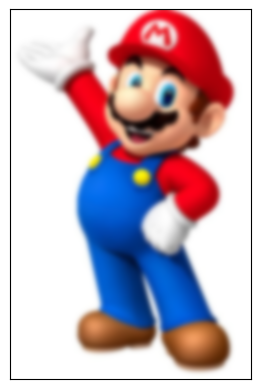

In [181]:
img_gaussian_color = cv.GaussianBlur(img_color, (25, 25), 0)

plt.xticks([]), plt.yticks([])
plt.imshow(cv.cvtColor(img_gaussian_color, cv.COLOR_BGR2RGB))

### Filtros máximos y mínimos:

Los filtros máximos y mínimos consisten en ordenar los niveles de gris de un entorno del pixel (x,y) procesado en cada instante, de menor a mayor, y cambiar el valor f(x,y) por el valor máximo (último) y mínimo (primero) de dicha ordenación. Las funciones de opencv que realizan dichos filtros son: 

    - Filtro máximo: cv.dilate(image, ksize) 
    - Filtro mínimo: cv.erode(image, ksize)

donde ksize = (ancho, alto) determina el tamaño del entorno. El filtro máximo es útil para eliminar ruido pimienta y el filtro mínimo el ruido sal.

1. Filtro Máximo (cv.dilate): Ordena los valores del entorno y sustituye el píxel por el más brillante (valor máximo / más blanco). "Agranda" las zonas claras y rellena o tapa los puntos oscuros. Es ideal para eliminar ruido pimienta (puntos negros), porque al buscar el máximo en el vecindario, sustituye el punto negro ($0$) por el color más claro que tenga alrededor.  

2. Filtro Mínimo (cv.erode): Ordena los valores del entorno y sustituye el píxel por el más oscuro (valor mínimo / más negro). "Agranda" las zonas oscuras y engulle los puntos blancos. Es ideal para eliminar ruido sal (puntos blancos), ya que el valor blanco ($255$) se reemplaza por el píxel más oscuro cercano.

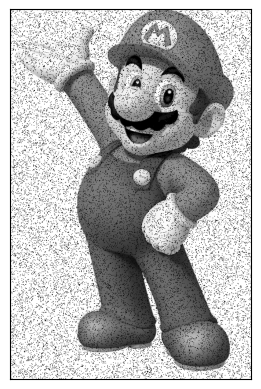

In [115]:
img_ruido_pimienta = ruido(img, 0.1, 0)
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido_pimienta, cmap = 'gray', vmin = 0, vmax = 255)

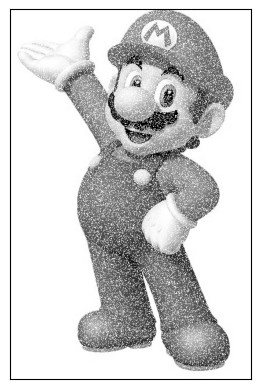

In [116]:
img_ruido_sal = ruido(img, 0, 0.2)
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido_sal, cmap = 'gray', vmin = 0, vmax = 255)

In [117]:
img_max = cv.dilate(img_ruido_pimienta, (25,25))
img_min = cv.erode(img_ruido_sal, (25,25))

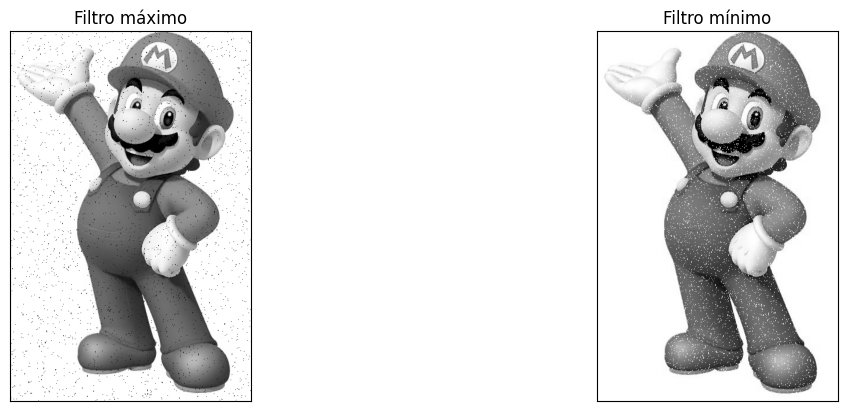

In [118]:
plt.subplots_adjust(left = None, bottom = None, right = 1.5, top = None, wspace = 1, hspace = 1) #ajustes del subplot

plt.subplot(1,2,1)
plt.title('Filtro máximo')
plt.xticks([]), plt.yticks([])
plt.imshow(img_max, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,2,2)
plt.title('Filtro mínimo')
plt.xticks([]), plt.yticks([])
plt.imshow(img_min, cmap = 'gray', vmin = 0, vmax = 255)

### Filtro de la mediana:

El filtro de la mediana consiste en ordenar los niveles de gris de un entorno del pixel (x,y) procesado en cada instante, de menor a mayor, y cambiar el valor f(x,y) por el valor central de dicha ordenación. La función de opencv que realiza este filtro es:

    - cv.medianBlur(image, ksize):

donde ksize en este caso es un entero positivo e impar.

Este filtro es muy útil para eliminar el ruido sal y pimienta, por ello, vamos a aplicarlo a la imagen con ruida generada al principio del notebook. 

Toma los píxeles del entorno del tamaño del kernel (por ejemplo, en un kernel de $3 \times 3$, toma los $9$ píxeles).   
Los ordena de menor a mayor según su intensidad de gris.   
Elige el valor justo en la posición central (la mediana) y reemplaza el píxel con ese valor.   

In [106]:
img_mediana3 = cv.medianBlur(img_ruido, 3)
img_mediana5 = cv.medianBlur(img_ruido, 5)

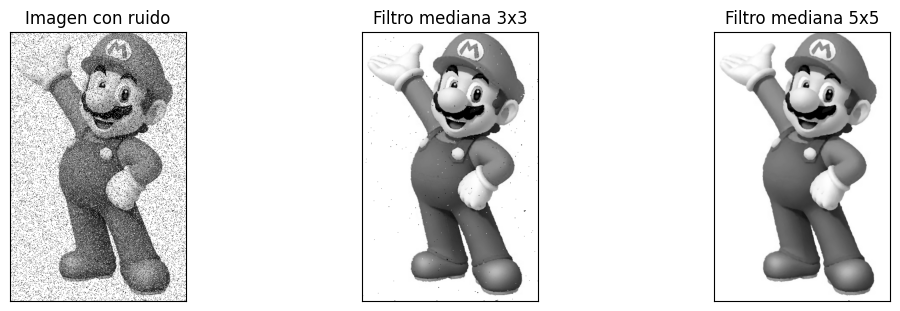

In [107]:
plt.subplots_adjust(left = None, bottom = None, right = 1.5, top = None, wspace = 1, hspace = 1) #ajustes del subplot

plt.subplot(1,3,1)
plt.title('Imagen con ruido')
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,2)
plt.title('Filtro mediana 3x3')
plt.xticks([]), plt.yticks([])
plt.imshow(img_mediana3, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,3)
plt.title('Filtro mediana 5x5')
plt.xticks([]), plt.yticks([])
plt.imshow(img_mediana5, cmap = 'gray', vmin = 0, vmax = 255)


In [184]:
img_mediana_gauss3 = cv.medianBlur(img_ruido_gauss2, 3)
img_mediana_gauss5 = cv.medianBlur(img_ruido_gauss2, 5)

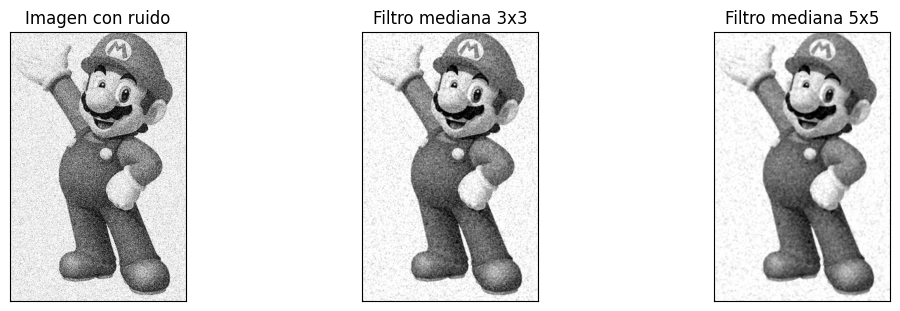

In [185]:
plt.subplots_adjust(left = None, bottom = None, right = 1.5, top = None, wspace = 1, hspace = 1) #ajustes del subplot

plt.subplot(1,3,1)
plt.title('Imagen con ruido')
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido_gauss2, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,2)
plt.title('Filtro mediana 3x3')
plt.xticks([]), plt.yticks([])
plt.imshow(img_mediana_gauss3, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,3)
plt.title('Filtro mediana 5x5')
plt.xticks([]), plt.yticks([])
plt.imshow(img_mediana_gauss5, cmap = 'gray', vmin = 0, vmax = 255)


# FILTROS DE REALCE:

## 2. Filtros de realce:

Los filtros de realce devuelven una imagen en escala de grises en la que:
* los cambios bruscos de intensidad de la imagen original se traducen en intensidades claras; 
* los cambios de intensidad más leves o nulos son más oscuros.

Tenemos dos tipos de filtros de realce:

* **Filtros gradiente (1ª derivada):** se calcula la matriz $M$ asociada al módulo del gradiente:

$$
M = \sqrt{G_x^2 + G_y^2} \approx |G_x| + |G_y|
$$

En dicha matriz, los elementos superiores a 0 indican cambios de intensidad en la imagen original (mientras mayores son los valores, más brusco son los cambios de intensidad). No tendrá elementos negativos al aplicar el módulo a partir de las matrices $G_x$ y $G_y$ pero si puede tener elementos superiores a 255.

Dependiendo de cómo sea la máscara que se use para obtener las matrices $G_x$ y $G_y$, se pueden definir distintos filtros:

- Roberts
- Prewitt
- Sobel


* **Filtro Laplaciano (2ª derivada):** se calcula una matriz que implementa el laplaciano de la imagen:

$$
\text{Laplaciano} = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}
$$

En este caso, se obtiene una matriz donde los elementos distintos de 0 (negativos o positivos) representarán cambios de intensidad en la imagen original. Dicha matriz puede tener elementos negativos y superiores a 255.

## Operador Sobel

El operador Sobel calcula el gradiente de la intensidad de la imagen en cada punto, dando la magnitud del mayor cambio posible y su dirección. OpenCV proporciona la función:

```python
cv.Sobel(src, ddepth, dx, dy, ksize)
```

Donde los parámetros son:
* `src`: imagen fuente/entrada
* `ddepth`: profundidad de la imagen destino. Se recomienda usar `cv.CV_64F` para detectar bordes tanto positivos como negativos
* `dx`: orden de la derivada en x (0 o 1)
* `dy`: orden de la derivada en y (0 o 1)
* `ksize`: tamaño del kernel Sobel (1, 3, 5, o 7)

Para obtener el gradiente completo necesitamos:

1. Gradiente en dirección X (`sobelx`): `dx=1, dy=0`

2. Gradiente en dirección Y (`sobely`): `dx=0, dy=1`

3. Combinamos ambos gradientes usando |Gx| + |Gy| para obtener todos los bordes

**Pasos típicos para usar Sobel:**
```python
# 1. Calcular gradientes
sobelx = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=3)  # Cambios en x -> Bordes verticales
sobely = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=3)  # Cambios en y -> Bordes horizontales

# 2. Convertir a valor absoluto
absobelx = np.absolute(sobelx)
absobely = np.absolute(sobely)

# 3. Combinar gradientes y convertir a uint8
sobel = np.clip(absobelx + absobely,0,255)
usobel = np.uint8(sobel)
```

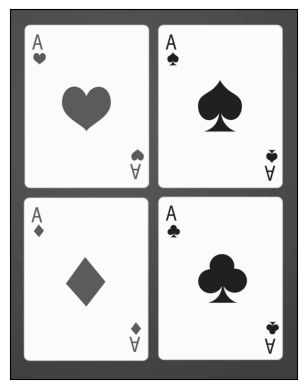

In [23]:
img2 = cv.imread('poker.jpg',0)

plt.xticks([]), plt.yticks([])
plt.imshow(img2, cmap = 'gray', vmin = 0, vmax = 255)

In [24]:
# Obtener kernels de Sobel para derivada en X (ksize=3)
kx, ky = cv.getDerivKernels(dx=1, dy=0, ksize=3, normalize=False)

# Convertir a arrays 2D
sobelx = ky @ kx.T   # Producto exterior para reconstruir el kernel

# Para derivada en Y
kx, ky = cv.getDerivKernels(dx=0, dy=1, ksize=3, normalize=False)
sobely = ky @ kx.T

print("Sobel X:\n", sobelx)
print("Sobel Y:\n", sobely)


Sobel X:
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
Sobel Y:
 [[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]


In [27]:
# 1. Calcular gradientes
sobelx = cv.Sobel(src = img2, ddepth = cv.CV_64F, dx = 1, dy = 0, ksize = 3)
sobely = cv.Sobel(src = img2, ddepth = cv.CV_64F, dx = 0, dy = 1, ksize = 3)

# 2. Convertir a valor absoluto
absobelx = np.absolute(sobelx)
absobely = np.absolute(sobely)

# 3. Combinar gradientes y convertir a uint8
sobel = np.clip(absobelx + absobely,0,255)
usobel = np.uint8(sobel)

In [28]:
sobelx.dtype,  np.min(sobelx), np.max(sobelx)

(dtype('float64'), -975.0, 961.0)

In [29]:
absobelx.dtype,  np.min(absobelx), np.max(absobelx)

(dtype('float64'), 0.0, 975.0)

In [30]:
sobel.dtype,  np.min(sobel), np.max(sobel)

(dtype('float64'), 0.0, 255.0)

In [31]:
usobel.dtype,  np.min(usobel), np.max(usobel)

(dtype('uint8'), 0, 255)

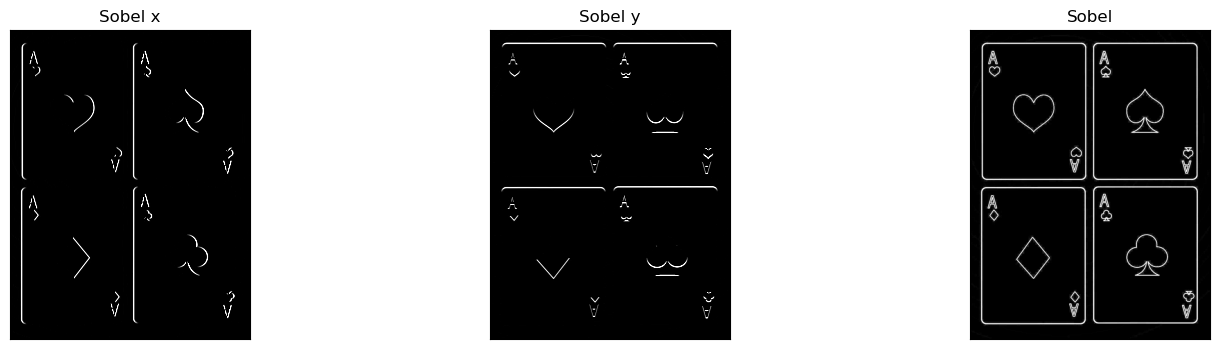

In [32]:
plt.subplots_adjust(left = None, bottom = None, right = 2, top = None, wspace = 1, hspace = 1) #ajustes del subplot

plt.subplot(1,3,1)
plt.title('Sobel x')
plt.xticks([]), plt.yticks([])
plt.imshow(sobelx, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,2)
plt.title('Sobel y')
plt.xticks([]), plt.yticks([])
plt.imshow(sobely, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,3)
plt.title('Sobel')
plt.xticks([]), plt.yticks([])
plt.imshow(sobel, cmap = 'gray', vmin = 0, vmax = 255)

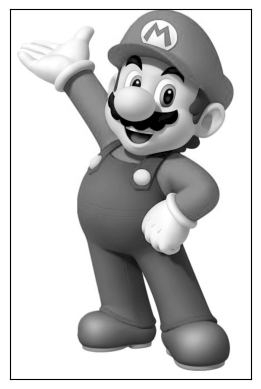

In [35]:
img2 = cv.imread('mario.png',0)

plt.xticks([]), plt.yticks([])
plt.imshow(img2, cmap = 'gray', vmin = 0, vmax = 255)

In [36]:
sobel_x = cv.Sobel(src = img2, ddepth = cv.CV_64F, dx = 1, dy = 0, ksize = 3)
sobel_y = cv.Sobel(src = img2, ddepth = cv.CV_64F, dx = 0, dy = 1, ksize = 3)

sobel_x = np.absolute(sobel_x)
sobel_y = np.absolute(sobel_y)

sobel = np.clip(sobel_x + sobel_y,0,255)
sobel = np.uint8(sobel)

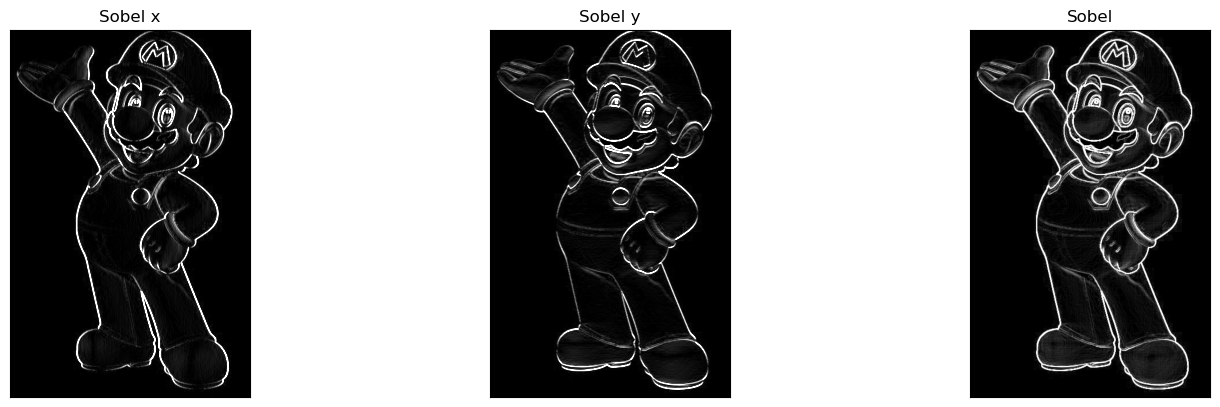

In [37]:
plt.subplots_adjust(left = None, bottom = None, right = 2, top = None, wspace = 1, hspace = 1) #ajustes del subplot

plt.subplot(1,3,1)
plt.title('Sobel x')
plt.xticks([]), plt.yticks([])
plt.imshow(sobel_x, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,2)
plt.title('Sobel y')
plt.xticks([]), plt.yticks([])
plt.imshow(sobel_y, cmap = 'gray', vmin = 0, vmax = 255)

plt.subplot(1,3,3)
plt.title('Sobel')
plt.xticks([]), plt.yticks([])
plt.imshow(sobel, cmap = 'gray', vmin = 0, vmax = 255)

## Laplaciano:

El Laplaciano se puede implementar digitalmente usando la siguiente máscara 3x3:

$$
\begin{equation}
\begin{bmatrix}
0 & 1 & 0\\
1 & -4 & 1\\ 
0 & 1 & 0 \\
\end{bmatrix}
\end{equation}
$$

Para aplicar el Laplaciano, usaremos la función de OpenCV

    - cv.Laplacian(src = im, ddepth = cv.CV_64F, ksize = 1)

donde `ksize = 1` indica que el kernel usado es el definido anteriormente.  

In [163]:
laplacian = cv.Laplacian(src = img2, ddepth = cv.CV_64F, ksize = 1)
laplacian = np.absolute(laplacian)
laplacian = np.uint8(laplacian)

imglap = cv.subtract(img2, laplacian)

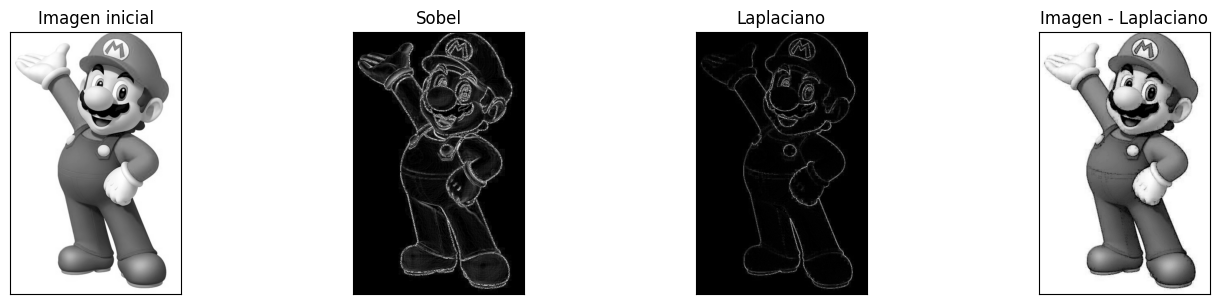

In [167]:
plt.subplots_adjust(left = None, bottom = None, right = 2, top = None, wspace = 1, hspace = 1) #ajustes del subplot

plt.subplot(1,4,1)
plt.title("Imagen inicial")
plt.xticks([]), plt.yticks([])
plt.imshow(img2, cmap = "gray",vmin = 0, vmax = 255)

plt.subplot(1,4,2)
plt.title("Sobel")
plt.xticks([]), plt.yticks([])
plt.imshow(sobel, cmap = "gray",vmin = 0, vmax = 255)

plt.subplot(1,4,3)
plt.title("Laplaciano")
plt.xticks([]), plt.yticks([])
plt.imshow(laplacian, cmap = "gray",vmin = 0, vmax = 255)

plt.subplot(1,4,4)
plt.title("Imagen - Laplaciano")
plt.xticks([]), plt.yticks([])
plt.imshow(imglap, cmap = "gray",vmin = 0, vmax = 255)

## Detector de bordes Canny

El detector de bordes Canny es uno de los más utilizados por su robustez. El algoritmo sigue varios pasos:

1. Reducción de ruido (aplica un filtro gaussiano)
2. Cálculo de gradientes (usando Sobel)
3. Supresión de no máximos
4. Umbralización con histéresis usando dos umbrales:
   - T1 (threshold1): umbral inferior
   - T2 (threshold2): umbral superior

La función de OpenCV es:
```python
cv.Canny(image, threshold1, threshold2, apertureSize=3, L2gradient=False)
```

Donde:
* `image`: imagen de entrada en escala de grises
* `threshold1`: umbral inferior (típicamente entre 20 y 150)
* `threshold2`: umbral superior (típicamente entre 60 y 250)
* `apertureSize`: tamaño del operador Sobel (3 por defecto)
* `L2gradient`: si es True, usa la magnitud del gradiente más precisa (√(Gx² + Gy²))

La umbralización con histéresis funciona así:
- Píxeles > T2: son considerados bordes fuertes
- Píxeles entre T1 y T2: son bordes débiles y solo se incluyen si están conectados a bordes fuertes
- Píxeles < T1: son descartados

Elegir buenos umbrales es crucial:
- T1 muy bajo: detecta demasiados bordes (falsos positivos)
- T2 muy alto: pierde bordes importantes (falsos negativos)
- Ratio típico T2:T1 entre 2:1 y 3:1

In [156]:
canny1 = cv.Canny(img, threshold1 = 90, threshold2 = 30)
canny2 = cv.Canny(img, threshold1 = 150, threshold2 = 50)
canny3 = cv.Canny(img, threshold1 = 180, threshold2 = 60)
canny4 = cv.Canny(img, threshold1 = 240, threshold2 = 80)

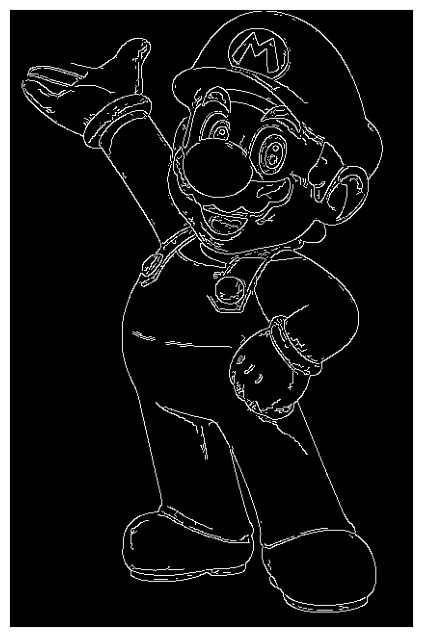

In [157]:
plt.figure(figsize = (8,8))
plt.xticks([]), plt.yticks([])
plt.imshow(canny1, cmap = "gray",vmin = 0, vmax = 255)

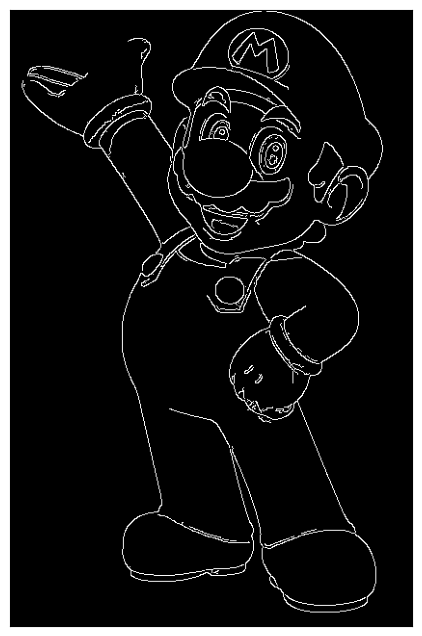

In [158]:
plt.figure(figsize = (8,8))
plt.xticks([]), plt.yticks([])
plt.imshow(canny2, cmap = "gray",vmin = 0, vmax = 255)

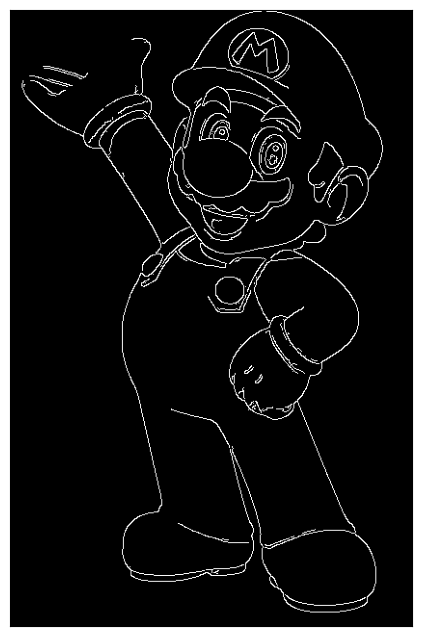

In [159]:
plt.figure(figsize = (8,8))
plt.xticks([]), plt.yticks([])
plt.imshow(canny3, cmap = "gray",vmin = 0, vmax = 255)

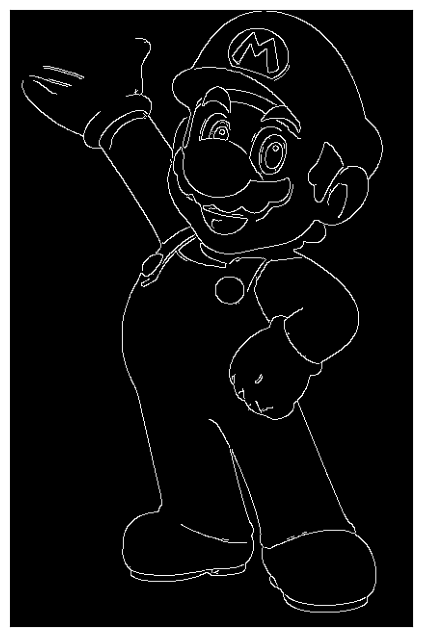

In [160]:
plt.figure(figsize = (8,8))
plt.xticks([]), plt.yticks([])
plt.imshow(canny4, cmap = "gray",vmin = 0, vmax = 255)